In [38]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

In [39]:
data = pd.read_csv('crx.data', header=None)
data

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,00202,0,+
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,00043,560,+
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,00280,824,+
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,00100,3,+
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,00120,0,+
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
685,b,21.08,10.085,y,p,e,h,1.25,f,f,0,f,g,00260,0,-
686,a,22.67,0.750,u,g,c,v,2.00,f,t,2,t,g,00200,394,-
687,a,25.25,13.500,y,p,ff,ff,2.00,f,t,1,t,g,00200,1,-
688,b,17.92,0.205,u,g,aa,v,0.04,f,f,0,f,g,00280,750,-


In [40]:
data.info() # 0, 3-6, 8-12 categorical features

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       690 non-null    object 
 1   1       690 non-null    object 
 2   2       690 non-null    float64
 3   3       690 non-null    object 
 4   4       690 non-null    object 
 5   5       690 non-null    object 
 6   6       690 non-null    object 
 7   7       690 non-null    float64
 8   8       690 non-null    object 
 9   9       690 non-null    object 
 10  10      690 non-null    int64  
 11  11      690 non-null    object 
 12  12      690 non-null    object 
 13  13      690 non-null    object 
 14  14      690 non-null    int64  
 15  15      690 non-null    object 
dtypes: float64(2), int64(2), object(12)
memory usage: 86.4+ KB


In [41]:
data.describe()

,2,7,10,14
count,690.000000,690.000000,690.00000,690.000000
mean,4.758725,2.223406,2.40000,1017.385507
std,4.978163,3.346513,4.86294,5210.102598
min,0.000000,0.000000,0.00000,0.000000
25%,1.000000,0.165000,0.00000,0.000000
50%,2.750000,1.000000,0.00000,5.000000
75%,7.207500,2.625000,3.00000,395.500000
max,28.000000,28.500000,67.00000,100000.000000


<Axes: >

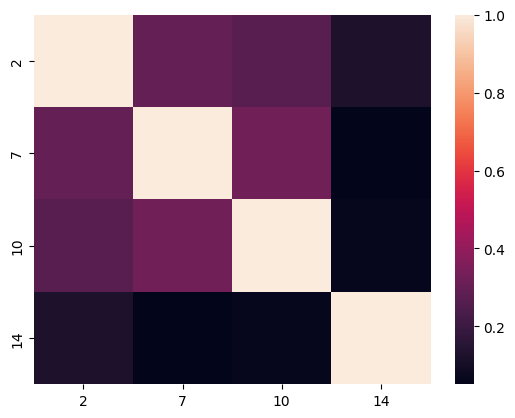

In [42]:
numerical = [2, 7, 10, 14]
corr_matrix = data[numerical].corr()
sns.heatmap(corr_matrix) # correlation is not high

In [43]:
data[0].value_counts()

,count
0,
b,468
a,210
?,12


In [44]:
data = data.replace('?', np.nan)
data[1] = data[1].astype('float')
data['stability_index'] = data[7]/data[1] # creating a new feature
data_clean = data.dropna()
data_clean

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,stability_index
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,00202,0,+,0.040545
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,00043,560,+,0.051815
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,00280,824,+,0.061224
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,00100,3,+,0.134747
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,00120,0,+,0.084779
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
685,b,21.08,10.085,y,p,e,h,1.25,f,f,0,f,g,00260,0,-,0.059298
686,a,22.67,0.750,u,g,c,v,2.00,f,t,2,t,g,00200,394,-,0.088222
687,a,25.25,13.500,y,p,ff,ff,2.00,f,t,1,t,g,00200,1,-,0.079208
688,b,17.92,0.205,u,g,aa,v,0.04,f,f,0,f,g,00280,750,-,0.002232


In [45]:
data_clean[0].value_counts()

,count
0,
b,450
a,203


In [46]:
data_encoded = pd.get_dummies(data_clean, columns=[0, 3, 4, 5, 6, 8, 9, 11, 12], drop_first=True, dtype=int)
data_encoded

,1,2,7,10,13,14,15,stability_index,0_b,3_u,...,6_j,6_n,6_o,6_v,6_z,8_t,9_t,11_t,12_p,12_s
0,30.83,0.000,1.25,1,00202,0,+,0.040545,1,1,...,0,0,0,1,0,1,1,0,0,0
1,58.67,4.460,3.04,6,00043,560,+,0.051815,0,1,...,0,0,0,0,0,1,1,0,0,0
2,24.50,0.500,1.50,0,00280,824,+,0.061224,0,1,...,0,0,0,0,0,1,0,0,0,0
3,27.83,1.540,3.75,5,00100,3,+,0.134747,1,1,...,0,0,0,1,0,1,1,1,0,0
4,20.17,5.625,1.71,0,00120,0,+,0.084779,1,1,...,0,0,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
685,21.08,10.085,1.25,0,00260,0,-,0.059298,1,0,...,0,0,0,0,0,0,0,0,0,0
686,22.67,0.750,2.00,2,00200,394,-,0.088222,0,1,...,0,0,0,1,0,0,1,1,0,0
687,25.25,13.500,2.00,1,00200,1,-,0.079208,0,0,...,0,0,0,0,0,0,1,1,0,0
688,17.92,0.205,0.04,0,00280,750,-,0.002232,1,1,...,0,0,0,1,0,0,0,0,0,0


In [47]:
X = data_encoded.drop(columns=[15])
y = data_encoded[15].map({'+': 1, '-': 0})
X.columns = X.columns.astype(str)
scaler = StandardScaler()
scaler.fit(X)
data_scaled = scaler.transform(X)

In [48]:
data_train, data_test, target_train, target_test = train_test_split(data_scaled, y, test_size=0.2, random_state=42)
# x_train, x_val, y_train, y_val = train_test_split(data_train, target_train, test_size=0.2, random_state=42)

In [49]:
clf_1 = DecisionTreeClassifier(random_state=42)
clf_1.fit(data_train, target_train)
clf_1.score(data_train, target_train)

1.0

In [50]:
parameters_1 = {'criterion':['gini', 'entropy', 'log_loss'],'max_depth':[3, 5, 7, 10, 20, 40, 60, 80],
                'min_samples_split':[2, 5, 10, 15, 20], 'min_samples_leaf':[1, 2, 5, 10, 15, 20, 25]}
clf_1_opt = GridSearchCV(clf_1, parameters_1)
clf_1_opt.fit(data_train, target_train)
clf_1_opt.best_params_

{'criterion': 'entropy',
 'max_depth': 5,
 'min_samples_leaf': 20,
 'min_samples_split': 2}

In [51]:
final_model_1 = clf_1_opt.best_estimator_
final_model_1.score(data_train, target_train)

0.8908045977011494

In [52]:
clf_2 = KNeighborsClassifier()
clf_2.fit(data_train, target_train)
clf_2.score(data_train, target_train)

0.8639846743295019

In [53]:
parameters_2 = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance'], 'algorithm': ['ball_tree', 'kd_tree', 'brute'],
             'p':[1, 2, 3, 4, 5]}
clf_2_opt = GridSearchCV(clf_2, parameters_2)
clf_2_opt.fit(data_train, target_train)
clf_2_opt.best_params_

{'algorithm': 'ball_tree', 'n_neighbors': 9, 'p': 1, 'weights': 'distance'}

In [54]:
final_model_2 = clf_2_opt.best_estimator_
final_model_2.score(data_train, target_train)

1.0

In [55]:
clf_3 = LogisticRegression(max_iter=10000, random_state=42)
clf_3.fit(data_train, target_train)
clf_3.score(data_train, target_train)

0.9003831417624522

In [56]:
parameters_3 = {'C': [0.001, 0.01, 0.1, 1, 25, 50, 100], 'max_iter': [100, 300, 500, 1000, 2000, 5000, 10000]}
clf_3_opt = GridSearchCV(clf_3, parameters_3)
clf_3_opt.fit(data_train, target_train)
clf_3_opt.best_params_

{'C': 0.1, 'max_iter': 100}

In [57]:
final_model_3 = clf_3_opt.best_estimator_
final_model_3.score(data_train, target_train)

0.8984674329501916

In [58]:
predict_1 = final_model_1.predict(data_test)
predict_2 = final_model_2.predict(data_test)
predict_3 = final_model_3.predict(data_test)

In [59]:
print(final_model_1.score(data_test, target_test))
print(final_model_2.score(data_test, target_test))
print(final_model_3.score(data_test, target_test))

0.8778625954198473
0.8473282442748091
0.8396946564885496


In [60]:
print(classification_report(target_test, predict_1))

              precision    recall  f1-score   support

           0       0.92      0.87      0.89        76
           1       0.83      0.89      0.86        55

    accuracy                           0.88       131
   macro avg       0.87      0.88      0.88       131
weighted avg       0.88      0.88      0.88       131



In [61]:
print(classification_report(target_test, predict_2))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87        76
           1       0.84      0.78      0.81        55

    accuracy                           0.85       131
   macro avg       0.85      0.84      0.84       131
weighted avg       0.85      0.85      0.85       131



In [62]:
print(classification_report(target_test, predict_3))

              precision    recall  f1-score   support

           0       0.90      0.82      0.86        76
           1       0.77      0.87      0.82        55

    accuracy                           0.84       131
   macro avg       0.84      0.84      0.84       131
weighted avg       0.85      0.84      0.84       131



As we can see, the best model for predicting credit approval is decision tree according to precision and recall